In [1]:
import sys
from pathlib import Path
import geopandas as gpd, pandas as pd, numpy as np
import matplotlib, folium, shapely, pyproj

print("Python:", sys.version.split()[0])
for m in (gpd, pd, np, matplotlib, folium, shapely, pyproj):
    print(f"{m.__name__:12s}", m.__version__)

# Find the repo root whether VS Code runs from the root or from notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("\nROOT:", ROOT)

def list_spatial(folder):
    exts = {".shp", ".gpkg", ".geojson"}
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in exts)

print("\nRGI files:")
for p in list_spatial(ROOT / "data" / "raw" / "rgi7"):
    print("  ", p.relative_to(ROOT))

print("\nBoundary files:")
for p in list_spatial(ROOT / "data" / "raw" / "boundary"):
    print("  ", p.relative_to(ROOT))

Python: 3.11.17
geopandas    1.2.0
pandas       3.0.6
numpy        2.4.6
matplotlib   3.11.2
folium       0.20.0
shapely      2.2.0
pyproj       3.7.2

ROOT: d:\nepal-glacier-explorer

RGI files:
   data\raw\rgi7\RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west.shp
   data\raw\rgi7\RGI2000-v7.0-G-15_south_asia_east\RGI2000-v7.0-G-15_south_asia_east.shp

Boundary files:
   data\raw\boundary\geoBoundaries-NPL-ADM0-all\geoBoundaries-NPL-ADM0.geojson
   data\raw\boundary\geoBoundaries-NPL-ADM0-all\geoBoundaries-NPL-ADM0.shp
   data\raw\boundary\geoBoundaries-NPL-ADM0-all\geoBoundaries-NPL-ADM0_simplified.geojson
   data\raw\boundary\geoBoundaries-NPL-ADM0-all\geoBoundaries-NPL-ADM0_simplified.shp


In [2]:
from pyogrio import read_info

rgi_dir = ROOT / "data" / "raw" / "rgi7"

# 1) Everything that came with the download (looking for CSV / JSON next to the .shp)
print("All files in RGI folders:")
for p in sorted(rgi_dir.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(rgi_dir)}  ({p.stat().st_size / 1e6:.2f} MB)")

# 2) Schema of each RGI shapefile (first 3 rows only, fast)
rgi_files = [p for p in list_spatial(rgi_dir) if p.suffix == ".shp"]
for f in rgi_files:
    info = read_info(f)
    g = gpd.read_file(f, rows=3)
    print("\n" + "=" * 70)
    print(f.name)
    print("Feature count:", info["features"], "| CRS:", g.crs)
    print("\nColumns and dtypes:")
    print(g.dtypes.to_string())
    print("\nFirst record (transposed):")
    print(g.drop(columns="geometry").iloc[0].to_string())

# 3) Boundary files: full and simplified versions
bdir = ROOT / "data" / "raw" / "boundary" / "geoBoundaries-NPL-ADM0-all"
for name in ["geoBoundaries-NPL-ADM0.shp", "geoBoundaries-NPL-ADM0_simplified.shp"]:
    b = gpd.read_file(bdir / name)
    print("\n" + "=" * 70)
    print(name, "| rows:", len(b), "| CRS:", b.crs)
    print(b.drop(columns="geometry").iloc[0].to_string())
    print("Bounds (minx, miny, maxx, maxy):", b.total_bounds.round(3))

All files in RGI folders:
  RGI2000-v7.0-G-14_south_asia_west\README.md  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-attributes.csv  (10.09 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-attributes_metadata.json  (0.01 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-hypsometry.csv  (11.57 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-rgi6_links.csv  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-submission_info.csv  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west-submission_info_metadata.json  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west.cpg  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west.dbf  (37.75 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14_south_asia_west.prj  (0.00 MB)
  RGI2000-v7.0-G-14_south_asia_west\RGI2000-v7.0-G-14

In [3]:
import json

d15 = rgi_dir / "RGI2000-v7.0-G-15_south_asia_east"

print("=== README ===")
print((d15 / "README.md").read_text(encoding="utf-8")[:2000])

print("\n=== attributes metadata (JSON) ===")
meta = json.loads((d15 / "RGI2000-v7.0-G-15_south_asia_east-attributes_metadata.json").read_text(encoding="utf-8"))
print(json.dumps(meta, indent=1)[:12000])

print("\n=== hypsometry CSV ===")
hyp = pd.read_csv(d15 / "RGI2000-v7.0-G-15_south_asia_east-hypsometry.csv", nrows=3)
print("Shape of preview:", hyp.shape)
cols = list(hyp.columns)
print("First 10 columns:", cols[:10])
print("Last 5 columns :", cols[-5:])
print(hyp.iloc[:, :8].to_string())

=== README ===
# The Randolph Glacier Inventory (RGI) version 7

RGI 7.0 Consortium, 2023. Randolph Glacier Inventory - A Dataset of Global Glacier Outlines, Version 7.0. Boulder, Colorado USA. NSIDC: National Snow and Ice Data Center. doi:10.5067/f6jmovy5navz. Online access: https://doi.org/10.5067/f6jmovy5navz 

Documentation: https://www.glims.org/rgi_user_guide


=== attributes metadata (JSON) ===
{
 "rgi_id": {
  "long_name": "RGI identifier",
  "description": "Unique identifier assigned to a single outline.",
  "datatype": "str",
  "units": "",
  "source": "RGI",
  "rgi6_name": "RGI_Id"
 },
 "o1region": {
  "long_name": "First order region",
  "description": "The code of the first-order region to which the glacier belongs.",
  "datatype": "str",
  "units": "",
  "source": "RGI",
  "rgi6_name": "O1Region"
 },
 "o2region": {
  "long_name": "Second order region",
  "description": "The code of the second-order region to which the glacier belongs.",
  "datatype": "str",
  "units": "",

Loaded 56,149 glaciers in 1 s | CRS: EPSG:4326

Glaciers and total area per region (RGI-provided area_km2):
              n  area_km2
o1region                 
14        37562   33075.0
15        18587   16049.0

Duplicate rgi_id      : 0
Invalid geometries    : 0
Empty geometries      : 0

Columns with nulls:
 glac_name    53898

Glaciers where RGI centre point and geometric centroid disagree on 'inside Nepal': 13

Glaciers overlapping Nepal at all: 4,679
                               n  area_rgi_km2  area_aea_km2
o1region centroid_in_nepal                                  
14       False                24          41.8          41.8
         True                 10           4.1           4.1
15       False               175         999.8         999.8
         True               4470        4240.7        4240.7

|area_aea - area_km2| as % of area_km2: median 0.00%, max 0.00%

Saved: data\processed\nepal_glaciers.gpkg


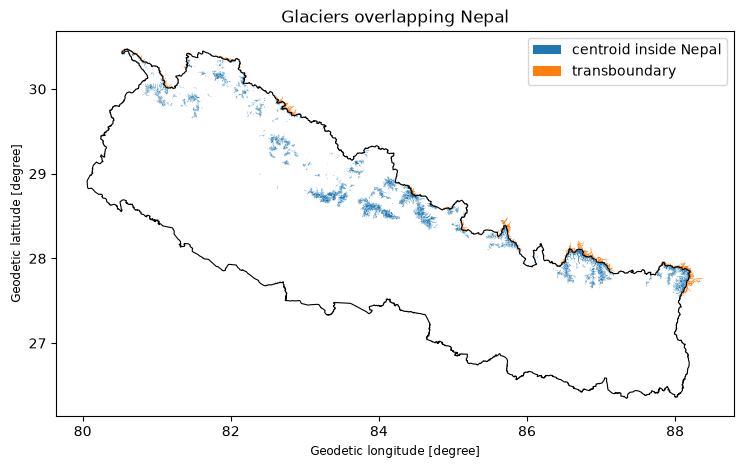

In [4]:
import time
t0 = time.time()

# Custom Albers equal-area CRS centred on Nepal (used for all area calculations)
AEA = "+proj=aea +lat_1=27 +lat_2=30 +lat_0=28.5 +lon_0=84 +datum=WGS84 +units=m +no_defs"

# ---- 1. Load and merge regions 14 and 15 ----
parts = [gpd.read_file(f, engine="pyogrio") for f in rgi_files]
assert parts[0].crs == parts[1].crs, "CRS mismatch between regions"
rgi = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=parts[0].crs)
print(f"Loaded {len(rgi):,} glaciers in {time.time()-t0:.0f} s | CRS: {rgi.crs}")

# ---- 2. Basic QA on the full dataset ----
print("\nGlaciers and total area per region (RGI-provided area_km2):")
print(rgi.groupby("o1region").agg(n=("rgi_id", "size"), area_km2=("area_km2", "sum")).round(0))

print("\nDuplicate rgi_id      :", rgi["rgi_id"].duplicated().sum())
print("Invalid geometries    :", (~rgi.geometry.is_valid).sum())
print("Empty geometries      :", rgi.geometry.is_empty.sum())
nulls = rgi.drop(columns="geometry").isna().sum()
print("\nColumns with nulls:\n", nulls[nulls > 0].to_string() if (nulls > 0).any() else "none")

# ---- 3. Nepal boundary (full resolution) ----
bdir = ROOT / "data" / "raw" / "boundary" / "geoBoundaries-NPL-ADM0-all"
nepal = gpd.read_file(bdir / "geoBoundaries-NPL-ADM0.shp").geometry.union_all()

# ---- 4. Candidate glaciers: bounding-box prefilter, then true intersection ----
minx, miny, maxx, maxy = nepal.bounds
cand = rgi.cx[minx:maxx, miny:maxy].copy()
cand = cand[cand.intersects(nepal)].copy()

# Rule: a glacier belongs to Nepal if its RGI centre point (cenlon, cenlat) is inside Nepal.
pts = gpd.GeoSeries(gpd.points_from_xy(cand["cenlon"], cand["cenlat"]), index=cand.index, crs="EPSG:4326")
cand["centroid_in_nepal"] = pts.within(nepal)
cand["transboundary"] = ~cand["centroid_in_nepal"]

# ---- 5. Areas recomputed in the equal-area CRS ----
cand_aea = cand.to_crs(AEA)
cand["area_aea_km2"] = cand_aea.area / 1e6

# Robustness check: do we get the same answer using the geometric centroid instead?
geo_cent = gpd.GeoSeries(cand_aea.centroid, crs=AEA).to_crs("EPSG:4326")
alt_inside = geo_cent.within(nepal)
print(f"\nGlaciers where RGI centre point and geometric centroid disagree on 'inside Nepal': "
      f"{(alt_inside != cand['centroid_in_nepal']).sum()}")

# ---- 6. Summary ----
print(f"\nGlaciers overlapping Nepal at all: {len(cand):,}")
summary = (cand.groupby(["o1region", "centroid_in_nepal"])
               .agg(n=("rgi_id", "size"),
                    area_rgi_km2=("area_km2", "sum"),
                    area_aea_km2=("area_aea_km2", "sum")).round(1))
print(summary)

pct = ((cand["area_aea_km2"] - cand["area_km2"]) / cand["area_km2"] * 100).abs()
print(f"\n|area_aea - area_km2| as % of area_km2: median {pct.median():.2f}%, max {pct.max():.2f}%")

# ---- 7. Save the working subset ----
out = ROOT / "data" / "processed" / "nepal_glaciers.gpkg"
cand.to_file(out, layer="glaciers", driver="GPKG", engine="pyogrio")
print("\nSaved:", out.relative_to(ROOT))

# ---- 8. Quick visual check ----
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
gpd.GeoSeries([nepal], crs="EPSG:4326").boundary.plot(ax=ax, color="k", lw=0.8)
cand[cand["centroid_in_nepal"]].plot(ax=ax, color="tab:blue", label="centroid inside Nepal")
cand[cand["transboundary"]].plot(ax=ax, color="tab:orange", label="transboundary")
ax.legend(); ax.set_title("Glaciers overlapping Nepal")
plt.show()

In [5]:
# ---- A. Area agreement with more decimals ----
rel = ((cand["area_aea_km2"] - cand["area_km2"]) / cand["area_km2"]).abs() * 100
print(f"Area agreement (Albers vs RGI): median {rel.median():.6f}% | max {rel.max():.6f}%")

# ---- B. Sensitivity: centre point inside Nepal vs any overlap ----
core = cand[cand["centroid_in_nepal"]]
print(f"\nCentre point inside Nepal : {len(core):,} glaciers, {core['area_aea_km2'].sum():,.1f} km2")
print(f"Any overlap with Nepal    : {len(cand):,} glaciers, {cand['area_aea_km2'].sum():,.1f} km2")

# ---- C. Attribute sanity ----
print("\nGlaciers per second-order region:")
print(cand.groupby(["o1region", "o2region", "centroid_in_nepal"]).size().to_string())

num_cols = ["area_km2", "zmin_m", "zmax_m", "zmed_m", "zmean_m", "slope_deg", "aspect_deg"]
print("\nNegative values (possible missing-data sentinels):")
print((cand[num_cols] < 0).sum().to_string())
print("\nzmin > zmax              :", (cand.zmin_m > cand.zmax_m).sum())
print("zmed outside [zmin,zmax] :", ((cand.zmed_m < cand.zmin_m) | (cand.zmed_m > cand.zmax_m)).sum())
print("area <= 0                :", (cand.area_km2 <= 0).sum())
print("aspect outside 0-360     :", ((cand.aspect_deg < 0) | (cand.aspect_deg > 360)).sum())

cand["src_year"] = pd.to_datetime(cand["src_date"], errors="coerce").dt.year
print("\nOutline source year (inventory date variability):")
print(cand["src_year"].value_counts(dropna=False).sort_index().to_string())
print("\nDEM source:\n", cand["dem_source"].value_counts().to_string())

# ---- D. Does aspect_sec match 45-degree sectors of aspect_deg? ----
sec_from_deg = (((cand["aspect_deg"] + 22.5) % 360) // 45 + 1).astype(int)
print("\naspect_sec (rows) vs sector computed from aspect_deg (cols; 1=N, 2=NE ... 8=NW):")
print(pd.crosstab(cand["aspect_sec"], sec_from_deg))

# ---- E. Hypsometry CSVs for the Nepal glaciers ----
frames = []
for d in sorted(rgi_dir.iterdir()):
    if d.is_dir():
        frames.append(pd.read_csv(next(d.glob("*-hypsometry.csv"))))
col_sets = [set(f.columns) for f in frames]
print("\nSame bin columns in both regions:", col_sets[0] == col_sets[1])

hyp_all = pd.concat(frames, ignore_index=True).fillna(0)   # a missing bin means no glacier area there
bin_cols = sorted([c for c in hyp_all.columns if c not in ("rgi_id", "area_km2")], key=int)
bins = np.array(bin_cols, dtype=int)
print(f"{len(bins)} bins from {bins.min()} to {bins.max()} m, step(s): {np.unique(np.diff(bins))}")

h = hyp_all[hyp_all["rgi_id"].isin(cand["rgi_id"])].set_index("rgi_id")
print(f"Hypsometry rows for Nepal glaciers: {len(h):,} of {len(cand):,}")

rowsum = h[bin_cols].sum(axis=1)
print("\nRow sums of the bin columns:")
print(rowsum.describe().round(3).to_string())
print("\nRow sum / area_km2 (about 1 means the bins are in km2):")
print((rowsum / h["area_km2"]).describe().round(3).to_string())

# Do the occupied bins agree with zmin / zmax?
z = cand.set_index("rgi_id").loc[h.index, ["zmin_m", "zmax_m"]]
occ = h[bin_cols].to_numpy() > 0
lo = bins[occ.argmax(axis=1)]
hi = bins[occ.shape[1] - 1 - occ[:, ::-1].argmax(axis=1)]
print("\nLowest occupied bin minus zmin_m (m):")
print(pd.Series(lo - z["zmin_m"].to_numpy()).describe().round(1).to_string())
print("\nHighest occupied bin minus zmax_m (m):")
print(pd.Series(hi - z["zmax_m"].to_numpy()).describe().round(1).to_string())

# ---- F. Save the Nepal hypsometry for notebook 03 ----
h.reset_index().to_parquet(ROOT / "data" / "processed" / "nepal_hypsometry.parquet", index=False)
print("\nSaved: data/processed/nepal_hypsometry.parquet")

Area agreement (Albers vs RGI): median 0.000002% | max 0.001260%

Centre point inside Nepal : 4,480 glaciers, 4,244.8 km2
Any overlap with Nepal    : 4,679 glaciers, 5,286.4 km2

Glaciers per second-order region:
o1region  o2region  centroid_in_nepal
14        14-03     False                  24
                    True                   10
15        15-01     False                  92
                    True                 3320
          15-02     False                  83
                    True                 1150

Negative values (possible missing-data sentinels):
area_km2      0
zmin_m        0
zmax_m        0
zmed_m        0
zmean_m       0
slope_deg     0
aspect_deg    0

zmin > zmax              : 0
zmed outside [zmin,zmax] : 0
area <= 0                : 0
aspect outside 0-360     : 0

Outline source year (inventory date variability):
src_year
1992      72
1994    1369
1998     434
1999     937
2000      24
2001     400
2002     781
2005      33
2010     629

DEM source:
 d

C:\Users\LOQ\AppData\Local\Temp\ipykernel_4460\237463560.py:65: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h.reset_index().to_parquet(ROOT / "data" / "processed" / "nepal_hypsometry.parquet", index=False)



Saved: data/processed/nepal_hypsometry.parquet


In [6]:
# ---- A. Convert hypsometry from per-mille to km2 ----
h = h.copy()                                    # defragment (silences the warning)
frac = h[bin_cols].to_numpy() / 1000.0          # fraction of glacier area in each 50 m bin
bin_km2 = pd.DataFrame(frac * h[["area_km2"]].to_numpy(), index=h.index, columns=bin_cols)

print(f"Hypsometry total : {bin_km2.to_numpy().sum():,.1f} km2")
print(f"Sum of area_km2  : {h['area_km2'].sum():,.1f} km2")

# ---- B. Validate: rebuild mean and median elevation from the bins, compare with attributes ----
att = cand.set_index("rgi_id").loc[h.index]
mean_hyp = (frac * bins).sum(axis=1)
med_hyp = bins[(frac.cumsum(axis=1) >= 0.5).argmax(axis=1)]

d_mean = pd.Series(mean_hyp - att["zmean_m"].to_numpy(), index=h.index)
d_med = pd.Series(med_hyp - att["zmed_m"].to_numpy(), index=h.index)
big = att["area_km2"] > 1

print("\nMean elevation from bins minus zmean_m (m), all glaciers:")
print(d_mean.describe(percentiles=[.05, .5, .95]).round(1).to_string())
print("\nMedian elevation from bins minus zmed_m (m), all glaciers:")
print(d_med.describe(percentiles=[.05, .5, .95]).round(1).to_string())
print(f"\nGlaciers > 1 km2 ({big.sum()}): median |mean diff| = {d_mean[big].abs().median():.1f} m, "
      f"median |median diff| = {d_med[big].abs().median():.1f} m")

# ---- C. Re-save the Nepal subset (now includes src_year) and the km2 hypsometry ----
proc = ROOT / "data" / "processed"
out = proc / "nepal_glaciers.gpkg"
out.unlink(missing_ok=True)
cand.to_file(out, layer="glaciers", driver="GPKG", engine="pyogrio")
bin_km2.reset_index().to_parquet(proc / "nepal_hypsometry_km2.parquet", index=False)
print("\nSaved:", out.relative_to(ROOT), "and nepal_hypsometry_km2.parquet")

Hypsometry total : 5,286.4 km2
Sum of area_km2  : 5,286.4 km2

Mean elevation from bins minus zmean_m (m), all glaciers:
count    4679.0
mean        0.0
std         1.0
min        -7.8
5%         -1.5
50%         0.0
95%         1.4
max        15.4

Median elevation from bins minus zmed_m (m), all glaciers:
count    4679.0
mean       -0.2
std        14.5
min       -26.7
5%        -22.6
50%        -0.7
95%        22.3
max        32.2

Glaciers > 1 km2 (898): median |mean diff| = 0.5 m, median |median diff| = 13.2 m

Saved: data\processed\nepal_glaciers.gpkg and nepal_hypsometry_km2.parquet
